# 06 — Đánh giá & Đối sánh mô hình (Model Evaluation)

## 1. Mục tiêu
Notebook này giải thích và trực quan hóa **Bước 6** trong quy trình XAI-Football:
- Đánh giá toàn diện và đối sánh công bằng giữa các mô hình GNN (Tầng 2: GCN, MPNN, GATv2, GraphSAGE) và Baseline phi đồ thị (Tầng 3: Logistic Regression, Random Forest, ANN).
- Các độ đo: AUC-PR (chỉ số chính do mất cân bằng nhãn), AUC-ROC, F1, Precision, Recall, Brier score (đo độ calibration xác suất).
- Vẽ đường cong Precision-Recall (PR) và ROC curve từ dự đoán thực tế trên tập Test.
- Trực quan hóa Brier score phản ánh mức độ tin cậy của xác suất.
- Diễn giải kết quả thực tế một cách trung thực, khoa học và minh bạch.

## 2. Vị trí của bước trong pipeline
Đây là **Bước 6 — Đánh giá mô hình (`scripts/07_evaluate.py`, `scripts/06_train_baselines.py`, `src/xai_football/evaluation/`)**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import precision_recall_curve, roc_curve

# Gốc repo: chạy được cả khi kernel đứng ở notebooks/ (mặc định của Jupyter/nbconvert)
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs").is_dir())
figures_dir = REPO_ROOT / "results" / "figures" / "official"
figures_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 150

## 3. Input và nguồn dữ liệu
- Bảng đối sánh (mean ± std qua 5 seed): `results/tables/official/model_comparison.csv`
- Khoảng tin cậy 95% theo trận: `results/tables/official/model_metric_ci.csv`
- Kiểm định từng cặp mô hình: `results/tables/official/significance_tests.csv`
- Dự đoán trên tập test của từng seed: `experiments/official/<model>/<seed>/test_predictions.parquet`,
  `experiments/official/baselines/<seed>/test_predictions.parquet`

## 4. Config/script/module sử dụng
- Scripts: `scripts/07_evaluate.py`, `scripts/06_train_baselines.py`
- Module: `src/xai_football/evaluation/metrics.py`, `src/xai_football/evaluation/significance.py`.

## 5. Các bước xử lý & Đọc kết quả thực tế

In [2]:
model_comp_path = REPO_ROOT / "results" / "tables" / "official" / "model_comparison.csv"
if not model_comp_path.exists():
    raise FileNotFoundError(f"Thiếu file: {model_comp_path}. Vui lòng chạy: python scripts/07_evaluate.py --config configs/data.yaml")

df_models = pd.read_csv(model_comp_path)
show_cols = ["model", "tier", "n_runs", "complete", "auc_pr", "auc_pr_std", "auc_roc", "auc_roc_std",
             "f1", "f1_std", "brier_score", "brier_score_std", "val_auc_pr"]
print("=== BẢNG ĐỐI SÁNH TRÊN TẬP TEST (mean ± std qua seed) ===")
display(df_models[show_cols])

=== BẢNG ĐỐI SÁNH TRÊN TẬP TEST (mean ± std qua seed) ===


,model,tier,n_runs,complete,auc_pr,auc_pr_std,auc_roc,auc_roc_std,f1,f1_std,brier_score,brier_score_std,val_auc_pr
0,GCN (đề xuất),Tier 2 — GNN Backbone,5,True,0.4526,0.0048,0.8310,0.0013,0.4722,0.0065,0.1688,0.0058,0.4168
1,MPNN (đề xuất),Tier 2 — GNN Backbone,5,True,0.5996,0.0042,0.8757,0.0034,0.5762,0.0036,0.1302,0.0114,0.5847
2,GATv2 (baseline),Tier 2 — GNN Baseline,5,True,0.4620,0.0048,0.8407,0.0014,0.4934,0.0048,0.1534,0.0070,0.4373
3,GraphSAGE (baseline),Tier 2 — GNN Baseline,5,True,0.5159,0.0022,0.8504,0.0009,0.5139,0.0066,0.1460,0.0049,0.4903
4,Logistic Regression,Tier 3(a) — Non-graph Baseline,5,True,0.3378,0.0000,0.8221,0.0000,0.4531,0.0000,0.1847,0.0000,0.3517
5,Random Forest,Tier 3(a) — Non-graph Baseline,5,True,0.6198,0.0017,0.8855,0.0006,0.5892,0.0047,0.0868,0.0002,0.6079
6,ANN (MLP),Tier 3(a) — Non-graph Baseline,5,True,0.6117,0.0097,0.8839,0.0018,0.5822,0.0099,0.0787,0.0013,0.6087


## 6. Kết quả và cách diễn giải
### 6.1. Đối sánh AUC-PR & AUC-ROC giữa các mô hình

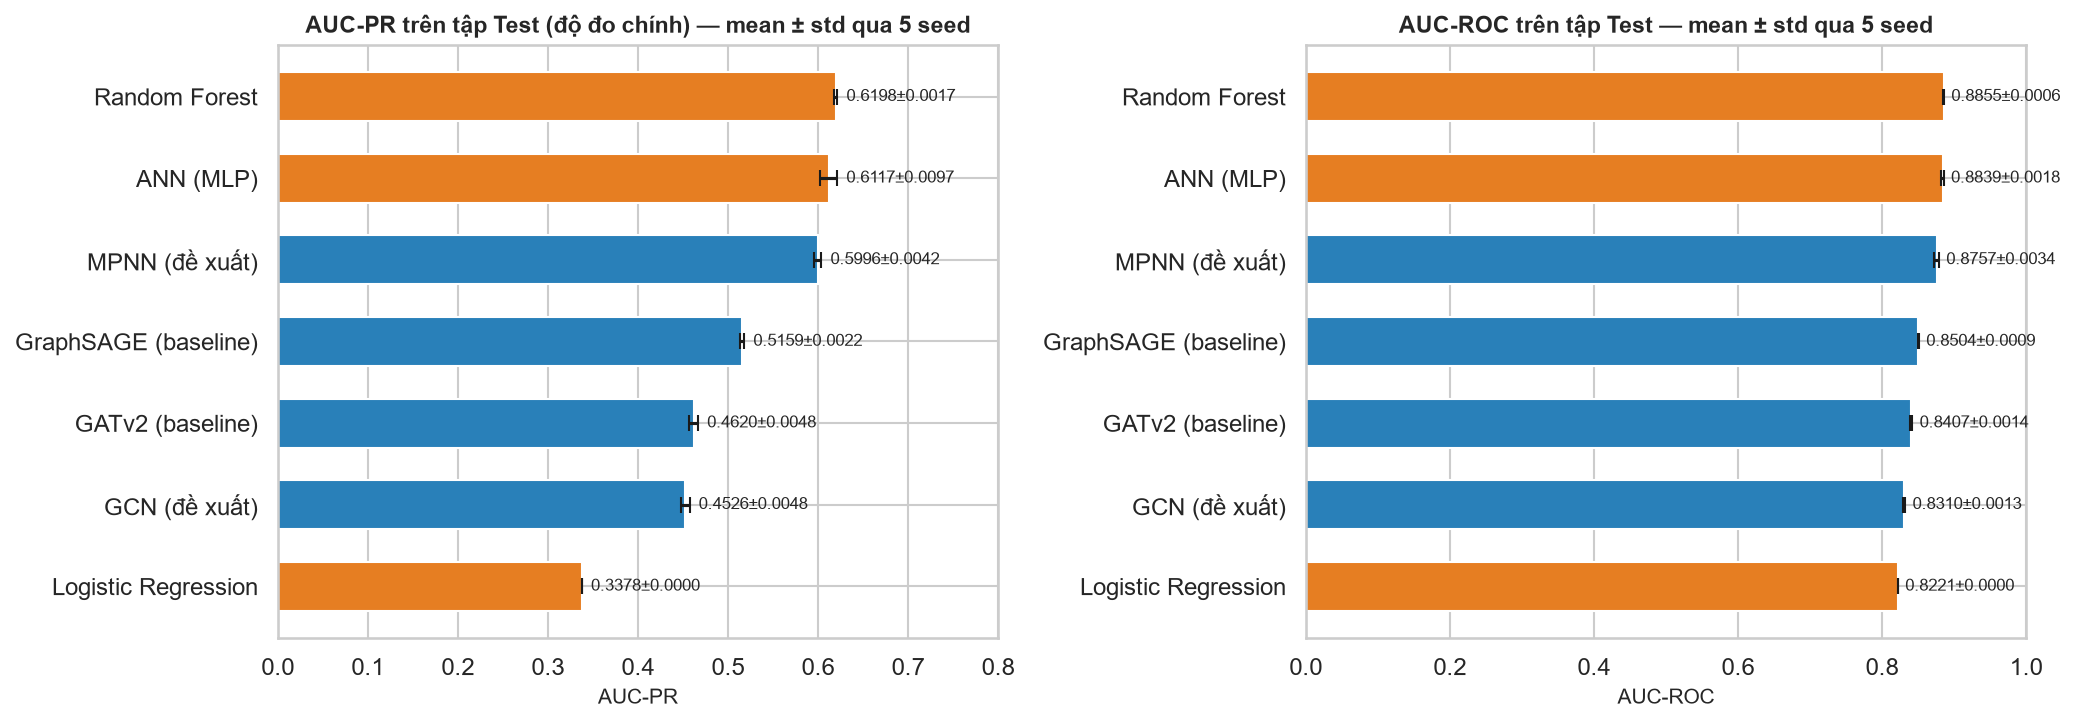

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df_sorted = df_models.sort_values("auc_pr", ascending=True)
colors = ["#2980b9" if "GNN" in str(t) else "#e67e22" for t in df_sorted["tier"]]

for ax, metric, title, xmax in ((axes[0], "auc_pr", "AUC-PR trên tập Test (độ đo chính)", 0.8),
                                (axes[1], "auc_roc", "AUC-ROC trên tập Test", 1.0)):
    ax.barh(df_sorted["model"], df_sorted[metric], xerr=df_sorted[f"{metric}_std"], color=colors, height=0.6, capsize=4)
    ax.set_title(title + " — mean ± std qua 5 seed", fontsize=11, fontweight="bold")
    ax.set_xlabel(metric.upper().replace("_", "-"), fontsize=10)
    ax.set_xlim(0, xmax)
    for y, (v, s) in enumerate(zip(df_sorted[metric], df_sorted[f"{metric}_std"])):
        ax.text(v + s + 0.01, y, f"{v:.4f}±{s:.4f}", va="center", fontsize=8)

plt.tight_layout()
plt.savefig(figures_dir / "06_model_auc_comparison.png", dpi=300)
plt.savefig(figures_dir / "06_model_auc_comparison.svg")
plt.show()

### 6.2. Đường cong Precision-Recall và ROC (Test Set)

Mỗi mô hình vẽ một seed đại diện: GNN dùng seed tốt nhất theo **validation** (không chọn theo test),
baseline cũng dùng seed tốt nhất theo validation của từng mô hình (cùng quy tắc). AUC-PR trong chú thích tính bằng `average_precision_score` — cùng công
thức với bảng kết quả (trước đây notebook dùng `auc(recall, precision)` nên số trên hình lệch bảng).

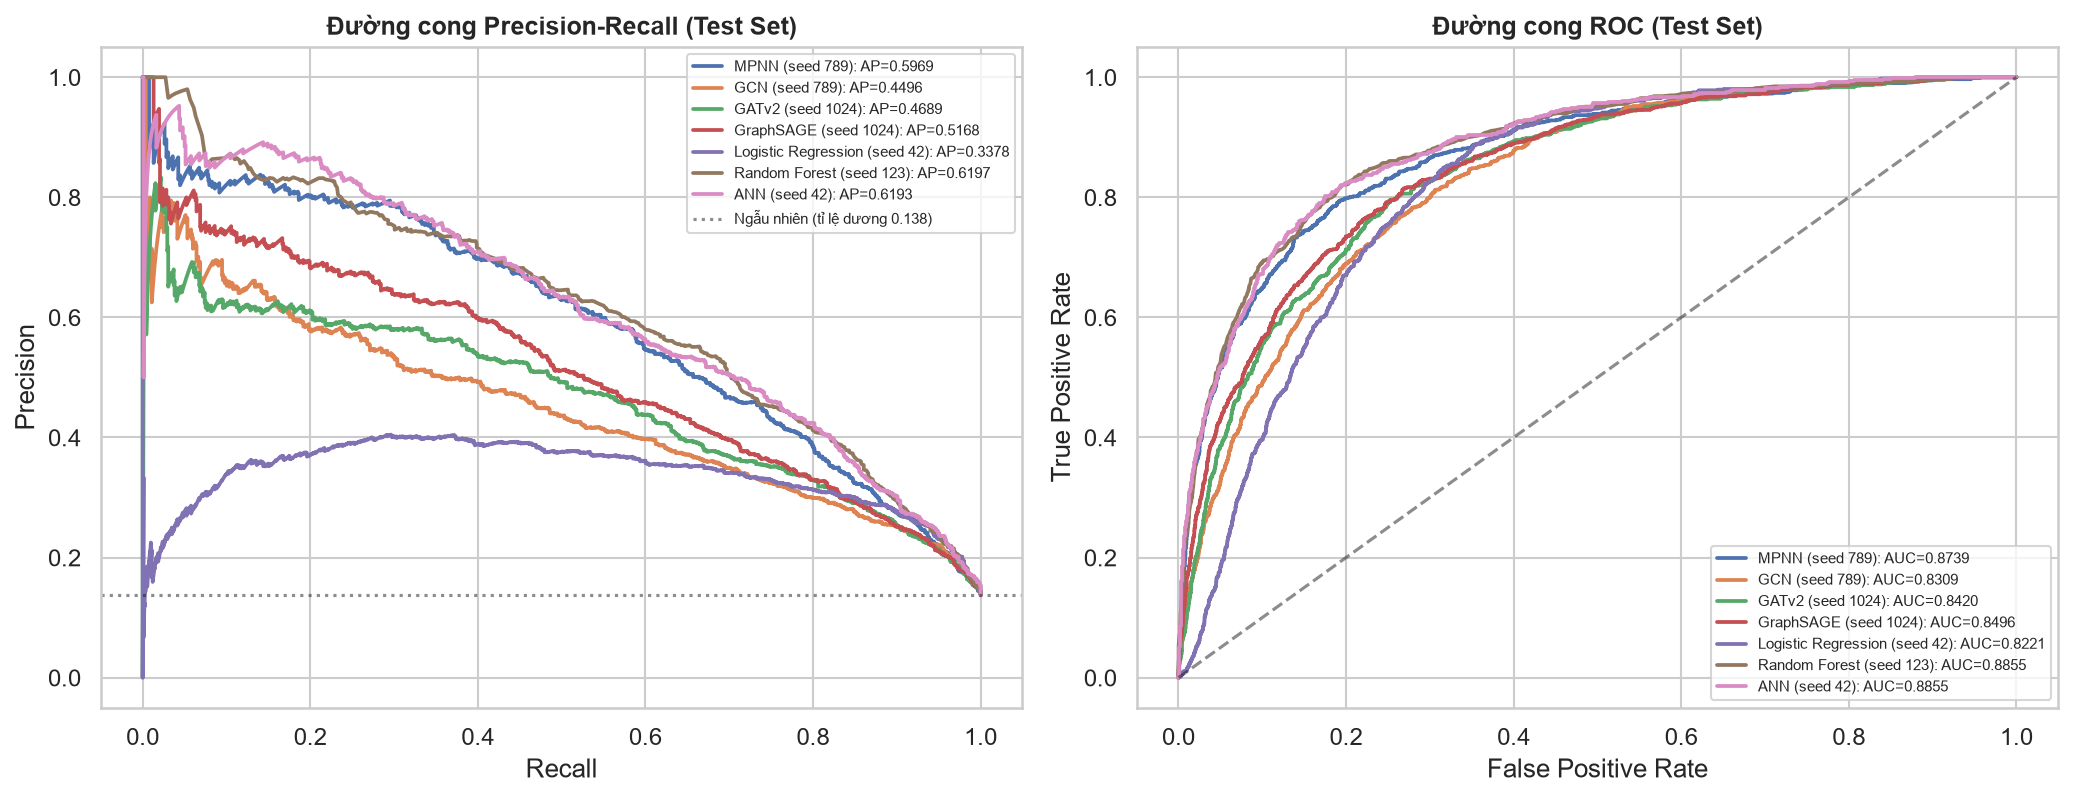

In [4]:
import json

from sklearn.metrics import average_precision_score, roc_auc_score

exp = REPO_ROOT / "experiments" / "official"
curves = {}
for display_name, key in (("MPNN", "mpnn"), ("GCN", "gcn"), ("GATv2", "gatv2"), ("GraphSAGE", "graphsage")):
    seed = json.loads((exp / key / "aggregate_summary.json").read_text(encoding="utf-8"))["best_seed_by_val_auc_pr"]
    df_p = pd.read_parquet(exp / key / str(seed) / "test_predictions.parquet")
    curves[f"{display_name} (seed {seed})"] = (df_p["y_true"].to_numpy(), df_p["y_prob"].to_numpy())
# Baseline: cùng quy tắc với GNN — seed có Val AUC-PR cao nhất của TỪNG mô hình
base_val = pd.read_csv(exp / "baselines" / "val_metrics_all_seeds.csv")
for display_name, key, col in (("Logistic Regression", "logistic_regression", "lr_prob"),
                               ("Random Forest", "random_forest", "rf_prob"), ("ANN", "ann", "ann_prob")):
    rows = base_val[base_val["model"] == key]
    seed = int(rows.loc[rows["auc_pr"].idxmax(), "seed"])
    df_b = pd.read_parquet(exp / "baselines" / str(seed) / "test_predictions.parquet")
    curves[f"{display_name} (seed {seed})"] = (df_b["y_true"].to_numpy(), df_b[col].to_numpy())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for label, (y, p) in curves.items():
    prec, rec, _ = precision_recall_curve(y, p)
    fpr, tpr, _ = roc_curve(y, p)
    axes[0].plot(rec, prec, lw=1.8, label=f"{label}: AP={average_precision_score(y, p):.4f}")
    axes[1].plot(fpr, tpr, lw=1.8, label=f"{label}: AUC={roc_auc_score(y, p):.4f}")

axes[0].axhline(y.mean(), color="k", ls=":", alpha=0.5, label=f"Ngẫu nhiên (tỉ lệ dương {y.mean():.3f})")
axes[0].set_title("Đường cong Precision-Recall (Test Set)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend(fontsize=7, loc="upper right")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_title("Đường cong ROC (Test Set)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.savefig(figures_dir / "06_pr_roc_curves.png", dpi=300)
plt.savefig(figures_dir / "06_pr_roc_curves.svg")
plt.show()

### 6.3. Brier Score — Độ tin cậy và Calibration của xác suất

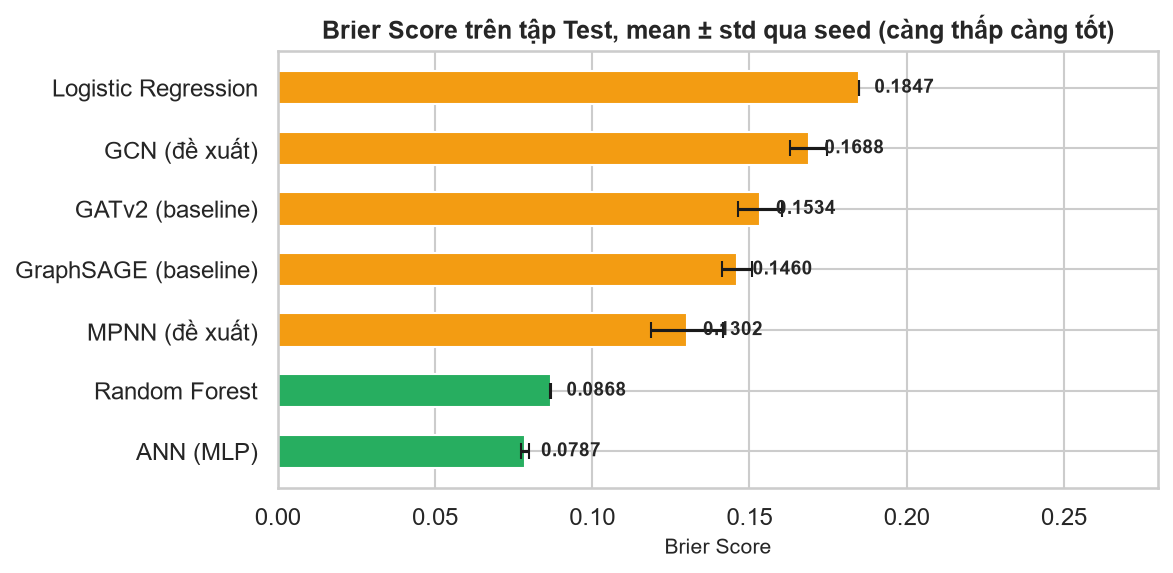

In [5]:
# Brier score càng thấp, mô hình dự đoán xác suất càng chuẩn xác
df_brier = df_models.dropna(subset=["brier_score"]).sort_values("brier_score", ascending=True)

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#27ae60" if b < 0.12 else "#f39c12" if b < 0.20 else "#e74c3c" for b in df_brier["brier_score"]]
bars = ax.barh(df_brier["model"], df_brier["brier_score"], xerr=df_brier["brier_score_std"], color=colors, height=0.55, capsize=4)
ax.set_title("Brier Score trên tập Test, mean ± std qua seed (càng thấp càng tốt)", fontsize=12, fontweight="bold")
ax.set_xlabel("Brier Score", fontsize=10)
ax.set_xlim(0, 0.28)

for b in bars:
    ax.text(b.get_width() + 0.005, b.get_y() + b.get_height() / 2, f"{b.get_width():.4f}", va="center", fontweight="bold", fontsize=9)

plt.tight_layout()
plt.savefig(figures_dir / "06_brier_score_comparison.png", dpi=300)
plt.savefig(figures_dir / "06_brier_score_comparison.svg")
plt.show()

### 6.4. Kiểm định ý nghĩa thống kê (paired cluster bootstrap theo trận)

Bảng mean ± std chỉ cho thấy dao động do seed. Để biết chênh lệch giữa hai mô hình có vượt qua
dao động do **chọn tập test** hay không, `scripts/07_evaluate.py` lấy mẫu lại 57 trận test có hoàn
lại (10.000 vòng), tính độ đo trung bình qua seed của từng mô hình trên **cùng** mẫu, rồi lấy khoảng
tin cậy 95% của chênh lệch. p-value được hiệu chỉnh Holm cho nhiều cặp. Kết luận ở bảng dưới được
sinh tự động từ dữ liệu, không ghi cứng.

Lưu ý khi đọc Brier score: GNN huấn luyện với `pos_weight` (≈ n_âm/n_dương) nên xác suất bị đẩy
lên, Brier của GNN vì thế kém hơn dù khả năng xếp hạng (AUC) tốt.

In [6]:
ci_df = pd.read_csv(REPO_ROOT / "results" / "tables" / "official" / "model_metric_ci.csv")
sig_df = pd.read_csv(REPO_ROOT / "results" / "tables" / "official" / "significance_tests.csv")

print("=== AUC-PR: giá trị và KTC 95% (bootstrap theo trận) ===")
display(ci_df[ci_df["metric"] == "auc_pr"].sort_values("value", ascending=False))

print("\n=== SO SÁNH TỪNG CẶP — AUC-PR (Holm) ===")
display(sig_df[sig_df["metric"] == "auc_pr"][["model_a", "model_b", "diff_a_minus_b", "ci95_low", "ci95_high", "p_value_holm", "verdict"]])

gnn = df_models[df_models["type"] == "Graph"].sort_values("val_auc_pr", ascending=False)
best_gnn = gnn.iloc[0]["model"]
best_all = df_models.sort_values("val_auc_pr", ascending=False).iloc[0]["model"]
print(f"\nGNN tốt nhất theo VALIDATION AUC-PR: {best_gnn}")
print(f"Mô hình tốt nhất theo VALIDATION AUC-PR (mọi tầng): {best_all}")
for _, r in sig_df[(sig_df["metric"] == "auc_pr") & ((sig_df["model_a"] == best_gnn) | (sig_df["model_b"] == best_gnn))].iterrows():
    print(f"  {r['model_a']} vs {r['model_b']}: chênh {r['diff_a_minus_b']:+.4f} "
          f"[{r['ci95_low']:+.4f}, {r['ci95_high']:+.4f}], p_Holm={r['p_value_holm']:.4f} -> {r['verdict']}")

=== AUC-PR: giá trị và KTC 95% (bootstrap theo trận) ===


,model,metric,n_seeds,value,ci95_low,ci95_high,n_boot_valid
5,Random Forest,auc_pr,5,0.6198,0.5833,0.6549,10000
6,ANN (MLP),auc_pr,5,0.6117,0.5776,0.6448,10000
1,MPNN (đề xuất),auc_pr,5,0.5996,0.5660,0.6324,10000
3,GraphSAGE (baseline),auc_pr,5,0.5159,0.4814,0.5507,10000
2,GATv2 (baseline),auc_pr,5,0.4620,0.4274,0.4971,10000
0,GCN (đề xuất),auc_pr,5,0.4526,0.4167,0.4891,10000
4,Logistic Regression,auc_pr,5,0.3378,0.3134,0.3658,10000



=== SO SÁNH TỪNG CẶP — AUC-PR (Holm) ===


,model_a,model_b,diff_a_minus_b,ci95_low,ci95_high,p_value_holm,verdict
0,GCN (đề xuất),MPNN (đề xuất),-0.1470,-0.1698,-0.1244,0.0042,MPNN (đề xuất) tốt hơn
1,GCN (đề xuất),GATv2 (baseline),-0.0095,-0.0262,0.0071,0.5103,không khác biệt có ý nghĩa
2,GCN (đề xuất),GraphSAGE (baseline),-0.0634,-0.0783,-0.0474,0.0042,GraphSAGE (baseline) tốt hơn
3,GCN (đề xuất),Logistic Regression,0.1147,0.0870,0.1402,0.0042,GCN (đề xuất) tốt hơn
4,GCN (đề xuất),Random Forest,-0.1673,-0.1954,-0.1383,0.0042,Random Forest tốt hơn
5,GCN (đề xuất),ANN (MLP),-0.1591,-0.1841,-0.1343,0.0042,ANN (MLP) tốt hơn
6,MPNN (đề xuất),GATv2 (baseline),0.1375,0.1132,0.1617,0.0042,MPNN (đề xuất) tốt hơn
7,MPNN (đề xuất),GraphSAGE (baseline),0.0836,0.0645,0.1035,0.0042,MPNN (đề xuất) tốt hơn
8,MPNN (đề xuất),Logistic Regression,0.2617,0.2360,0.2850,0.0042,MPNN (đề xuất) tốt hơn
9,MPNN (đề xuất),Random Forest,-0.0203,-0.0418,0.0016,0.2728,không khác biệt có ý nghĩa



GNN tốt nhất theo VALIDATION AUC-PR: MPNN (đề xuất)
Mô hình tốt nhất theo VALIDATION AUC-PR (mọi tầng): ANN (MLP)
  GCN (đề xuất) vs MPNN (đề xuất): chênh -0.1470 [-0.1698, -0.1244], p_Holm=0.0042 -> MPNN (đề xuất) tốt hơn
  MPNN (đề xuất) vs GATv2 (baseline): chênh +0.1375 [+0.1132, +0.1617], p_Holm=0.0042 -> MPNN (đề xuất) tốt hơn
  MPNN (đề xuất) vs GraphSAGE (baseline): chênh +0.0836 [+0.0645, +0.1035], p_Holm=0.0042 -> MPNN (đề xuất) tốt hơn
  MPNN (đề xuất) vs Logistic Regression: chênh +0.2617 [+0.2360, +0.2850], p_Holm=0.0042 -> MPNN (đề xuất) tốt hơn
  MPNN (đề xuất) vs Random Forest: chênh -0.0203 [-0.0418, +0.0016], p_Holm=0.2728 -> không khác biệt có ý nghĩa
  MPNN (đề xuất) vs ANN (MLP): chênh -0.0121 [-0.0264, +0.0018], p_Holm=0.2728 -> không khác biệt có ý nghĩa


## 7. Kiểm tra chất lượng (Quality Checks)

In [7]:
checks = []
checks.append({"Check": "Bảng model_comparison có đủ 7 mô hình", "Status": "PASS" if len(df_models) == 7 else "FAIL"})
checks.append({"Check": "Mọi mô hình đủ 5 seed (complete)", "Status": "PASS" if df_models["complete"].all() and (df_models["n_runs"] == 5).all() else "FAIL"})
checks.append({"Check": "AUC-PR nằm trong khoảng [0, 1]", "Status": "PASS" if ((df_models["auc_pr"] >= 0) & (df_models["auc_pr"] <= 1)).all() else "FAIL"})
checks.append({"Check": "Có kiểm định cho đủ 21 cặp × 3 độ đo", "Status": "PASS" if len(sig_df) == 63 else "FAIL"})

df_eval_checks = pd.DataFrame(checks)
display(df_eval_checks)
assert (df_eval_checks["Status"] == "PASS").all(), "Có kiểm tra đánh giá không đạt!"
# Không assert "MPNN phải tốt nhất": notebook ghi nhận kết quả, không ép kết quả theo giả thuyết.

,Check,Status
0,Bảng model_comparison có đủ 7 mô hình,PASS
1,Mọi mô hình đủ 5 seed (complete),PASS
2,"AUC-PR nằm trong khoảng [0, 1]",PASS
3,Có kiểm định cho đủ 21 cặp × 3 độ đo,PASS


## 8. Output được lưu ở đâu
- Bảng: `results/tables/official/model_comparison.csv`, `val_model_comparison.csv`,
  `model_metric_ci.csv`, `significance_tests.csv`, `baseline_comparison.csv`.
- Kết quả từng seed: `results/reproducibility/all_models_{test,val}_metrics_all_seeds.csv`.
- Manifest (sinh tự động): `results/metadata/official/experiment_manifest.json`, `evaluation_manifest.json`.
- Biểu đồ:
  - `results/figures/official/06_model_auc_comparison.png` (và `.svg`)
  - `results/figures/official/06_pr_roc_curves.png` (và `.svg`)
  - `results/figures/official/06_brier_score_comparison.png` (và `.svg`)

## 9. Cách tái chạy
```bash
python scripts/06_train_baselines.py --config configs/data.yaml
python scripts/07_evaluate.py --config configs/data.yaml
```

## 10. Giới hạn và giả định
- Notebook này chỉ đánh giá Bài toán 1 (Bước 6). Phần XAI (Bước 7 trở đi) nằm ngoài phạm vi notebook.
- Baseline dạng bảng dùng 10 đặc trưng passing path (`configs/model/baseline_tabular.yaml`), trích từ
  CHÍNH các đồ thị đã cắt trước cú sút — cùng thông tin đầu vào với GNN.
- Nhãn đang dùng tạm `possession_level` / `shot` (Decision 0001 chưa chốt).